In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error

print("MovieMatch project environment is ready!")

MovieMatch project environment is ready!


In [ ]:
import os
import zipfile
import urllib.request

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

zip_path = "ml-latest-small.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(".")

print("MovieLens dataset downloaded successfully!")

MovieLens dataset downloaded successfully!


In [ ]:
data_path = "ml-latest-small"

ratings = pd.read_csv(f"{data_path}/ratings.csv")
movies = pd.read_csv(f"{data_path}/movies.csv")
tags = pd.read_csv(f"{data_path}/tags.csv")
links = pd.read_csv(f"{data_path}/links.csv")

print("All dataset files loaded successfully!")

print("\nRatings:", ratings.shape)
print("Movies:", movies.shape)
print("Tags:", tags.shape)
print("Links:", links.shape)

All dataset files loaded successfully!

Ratings: (100836, 4)
Movies: (9742, 3)
Tags: (3683, 4)
Links: (9742, 3)


In [ ]:
print("RATINGS DATA")
display(ratings.head())

print("MOVIES DATA")
display(movies.head())

print("TAGS DATA")
display(tags.head())

print("MOVIE LINKS DATA")
display(links.head())

RATINGS DATA


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


MOVIES DATA


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


TAGS DATA


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


MOVIE LINKS DATA


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [ ]:

# 1. Check dataset dimensions
print("Dataset Dimensions")
print("Ratings:", ratings.shape)
print("Movies:", movies.shape)
print("Tags:", tags.shape)
print("Links:", links.shape)

# 2. Check column names
print("\nRatings Columns:", ratings.columns.tolist())
print("Movies Columns:", movies.columns.tolist())
print("Tags Columns:", tags.columns.tolist())
print("Links Columns:", links.columns.tolist())

# 3. Check missing values
print("\nMissing Values")
print("Ratings:\n", ratings.isnull().sum())
print("Movies:\n", movies.isnull().sum())
print("Tags:\n", tags.isnull().sum())
print("Links:\n", links.isnull().sum())

# 4. Check duplicate records
print("\nDuplicate Records")
print("Ratings:", ratings.duplicated().sum())
print("Movies:", movies.duplicated().sum())
print("Tags:", tags.duplicated().sum())
print("Links:", links.duplicated().sum())


Dataset Dimensions
Ratings: (100836, 4)
Movies: (9742, 3)
Tags: (3683, 4)
Links: (9742, 3)

Ratings Columns: ['userId', 'movieId', 'rating', 'timestamp']
Movies Columns: ['movieId', 'title', 'genres']
Tags Columns: ['userId', 'movieId', 'tag', 'timestamp']
Links Columns: ['movieId', 'imdbId', 'tmdbId']

Missing Values
Ratings:
 userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Movies:
 movieId    0
title      0
genres     0
dtype: int64
Tags:
 userId       0
movieId      0
tag          0
timestamp    0
dtype: int64
Links:
 movieId    0
imdbId     0
tmdbId     8
dtype: int64

Duplicate Records
Ratings: 0
Movies: 0
Tags: 0
Links: 0


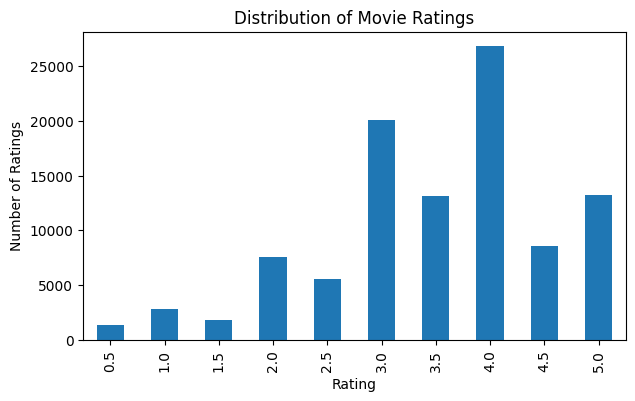

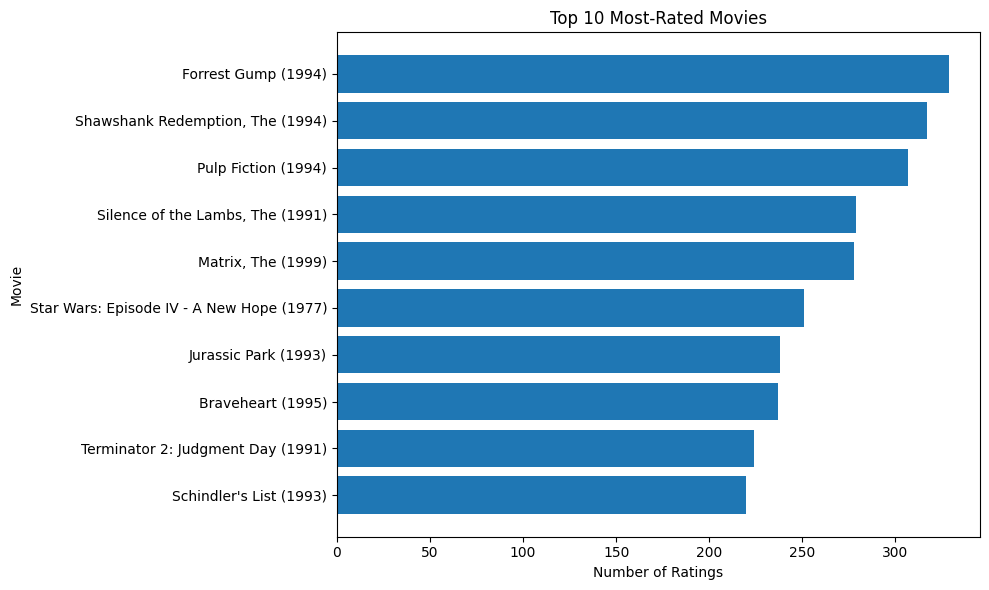

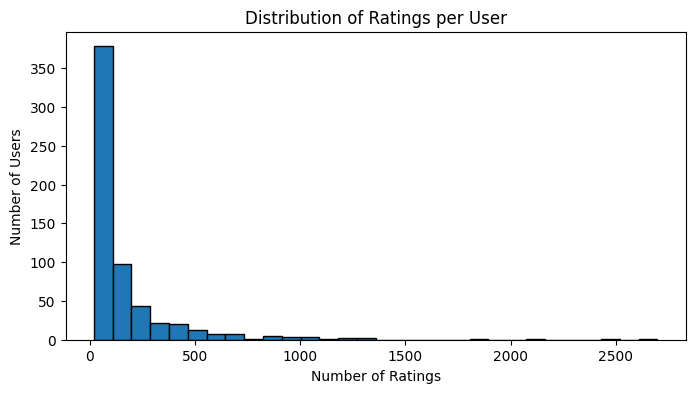

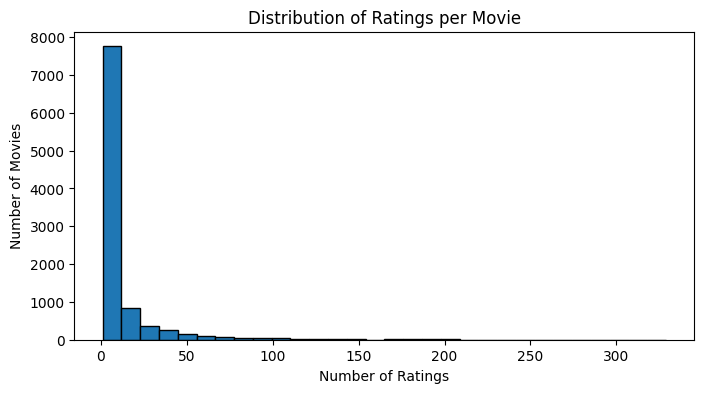

Total ratings: 100836
Unique users: 610
Unique movies rated: 9724
Average rating: 3.5
Rating standard deviation: 1.04


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ratings distribution
plt.figure(figsize=(7, 4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()


# 2. Top 10 most-rated movies
movie_rating_counts = ratings["movieId"].value_counts().head(10)

top_movies = movies[movies["movieId"].isin(movie_rating_counts.index)].copy()
top_movies["rating_count"] = top_movies["movieId"].map(movie_rating_counts)
top_movies = top_movies.sort_values("rating_count", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(top_movies["title"], top_movies["rating_count"])
plt.title("Top 10 Most-Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()


# 3. Number of ratings per user
user_rating_counts = ratings.groupby("userId").size()

plt.figure(figsize=(8, 4))
plt.hist(user_rating_counts, bins=30, edgecolor="black")
plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()


# 4. Number of ratings per movie
movie_counts = ratings.groupby("movieId").size()

plt.figure(figsize=(8, 4))
plt.hist(movie_counts, bins=30, edgecolor="black")
plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")
plt.show()


# 5. Dataset summary
print("Total ratings:", len(ratings))
print("Unique users:", ratings["userId"].nunique())
print("Unique movies rated:", ratings["movieId"].nunique())
print("Average rating:", round(ratings["rating"].mean(), 2))
print("Rating standard deviation:", round(ratings["rating"].std(), 2))


In [ ]:

# STEP 4: BASELINE RECOMMENDATION MODELS

# 1. Global Mean
global_mean = ratings["rating"].mean()

# 2. User Mean
user_mean = ratings.groupby("userId")["rating"].mean()

# 3. Movie Mean
movie_mean = ratings.groupby("movieId")["rating"].mean()

print("GLOBAL MEAN BASELINE")
print("Average rating across all users and movies:", round(global_mean, 3))

print("\nUSER MEAN BASELINE")
display(user_mean.head())

print("\nMOVIE MEAN BASELINE")
display(movie_mean.head())


# 4. Predict a rating for one user and one movie
sample_user = ratings.iloc[0]["userId"]
sample_movie = ratings.iloc[0]["movieId"]

print("\nSAMPLE PREDICTIONS")
print("User ID:", int(sample_user))
print("Movie ID:", int(sample_movie))
print("Global Mean Prediction:", round(global_mean, 3))
print("User Mean Prediction:", round(user_mean.loc[sample_user], 3))
print("Movie Mean Prediction:", round(movie_mean.loc[sample_movie], 3))
print("Actual Rating:", ratings.iloc[0]["rating"])



GLOBAL MEAN BASELINE
Average rating across all users and movies: 3.502

USER MEAN BASELINE


,rating
userId,
1,4.366379
2,3.948276
3,2.435897
4,3.555556
5,3.636364



MOVIE MEAN BASELINE


,rating
movieId,
1,3.920930
2,3.431818
3,3.259615
4,2.357143
5,3.071429



SAMPLE PREDICTIONS
User ID: 1
Movie ID: 1
Global Mean Prediction: 3.502
User Mean Prediction: 4.366
Movie Mean Prediction: 3.921
Actual Rating: 4.0


In [ ]:

# STEP 5: CHRONOLOGICAL TRAIN-TEST SPLIT

ratings_sorted = ratings.sort_values(
    ["userId", "timestamp"]
).copy()

# Keep each user's latest 20% of ratings for testing
ratings_sorted["rank"] = (
    ratings_sorted.groupby("userId").cumcount()
)

ratings_sorted["total_ratings"] = (
    ratings_sorted.groupby("userId")["rating"].transform("size")
)

ratings_sorted["test_start"] = (
    ratings_sorted["total_ratings"] * 0.8
).apply(np.ceil)

train_data = ratings_sorted[
    ratings_sorted["rank"] < ratings_sorted["test_start"]
].copy()

test_data = ratings_sorted[
    ratings_sorted["rank"] >= ratings_sorted["test_start"]
].copy()

# Remove temporary columns
train_data = train_data.drop(
    columns=["rank", "total_ratings", "test_start"]
)

test_data = test_data.drop(
    columns=["rank", "total_ratings", "test_start"]
)

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining users:", train_data["userId"].nunique())
print("Testing users:", test_data["userId"].nunique())

print("\nTraining time range:")
print(pd.to_datetime(train_data["timestamp"], unit="s").agg(["min", "max"]))

print("\nTesting time range:")
print(pd.to_datetime(test_data["timestamp"], unit="s").agg(["min", "max"]))


Training records: 80896
Testing records: 19940

Training users: 610
Testing users: 610

Training time range:
min   1996-03-29 18:36:55
max   2018-09-17 04:25:01
Name: timestamp, dtype: datetime64[ns]

Testing time range:
min   1996-03-29 18:36:56
max   2018-09-24 14:27:30
Name: timestamp, dtype: datetime64[ns]


In [ ]:

from sklearn.metrics import mean_squared_error

# Calculate baseline statistics using TRAINING DATA ONLY
global_mean_train = train_data["rating"].mean()

user_mean_train = train_data.groupby("userId")["rating"].mean()
movie_mean_train = train_data.groupby("movieId")["rating"].mean()


def calculate_rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))


# Global Mean predictions
global_predictions = np.full(
    len(test_data), global_mean_train
)

# User Mean predictions
user_predictions = test_data["userId"].map(
    user_mean_train
).fillna(global_mean_train)

# Movie Mean predictions
movie_predictions = test_data["movieId"].map(
    movie_mean_train
).fillna(global_mean_train)


# Evaluate each model
baseline_results = pd.DataFrame({
    "Model": [
        "Global Mean",
        "User Mean",
        "Movie Mean"
    ],
    "RMSE": [
        calculate_rmse(test_data["rating"], global_predictions),
        calculate_rmse(test_data["rating"], user_predictions),
        calculate_rmse(test_data["rating"], movie_predictions)
    ]
})

display(baseline_results.sort_values("RMSE"))


,Model,RMSE
1,User Mean,0.964804
2,Movie Mean,1.022708
0,Global Mean,1.068771


In [ ]:

# Combine movie genres and user-generated tags

tags_grouped = (
    tags.dropna(subset=["tag"])
    .groupby("movieId")["tag"]
    .apply(lambda x: " ".join(x.astype(str)))
)

content_movies = movies.copy()

content_movies["genres"] = (
    content_movies["genres"]
    .fillna("")
    .str.replace("|", " ", regex=False)
)

content_movies["tags_text"] = (
    content_movies["movieId"]
    .map(tags_grouped)
    .fillna("")
)

content_movies["features"] = (
    content_movies["genres"] + " " +
    content_movies["tags_text"]
).str.strip()

print("Movie features prepared!")
display(content_movies[["title", "genres", "tags_text", "features"]].head(10))



Movie features prepared!


,title,genres,tags_text,features
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy,pixar pixar fun,Adventure Animation Children Comedy Fantasy pi...
1,Jumanji (1995),Adventure Children Fantasy,fantasy magic board game Robin Williams game,Adventure Children Fantasy fantasy magic board...
2,Grumpier Old Men (1995),Comedy Romance,moldy old,Comedy Romance moldy old
3,Waiting to Exhale (1995),Comedy Drama Romance,,Comedy Drama Romance
4,Father of the Bride Part II (1995),Comedy,pregnancy remake,Comedy pregnancy remake
5,Heat (1995),Action Crime Thriller,,Action Crime Thriller
6,Sabrina (1995),Comedy Romance,remake,Comedy Romance remake
7,Tom and Huck (1995),Adventure Children,,Adventure Children
8,Sudden Death (1995),Action,,Action
9,GoldenEye (1995),Action Adventure Thriller,,Action Adventure Thriller


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(content_movies["features"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of movies:", tfidf_matrix.shape[0])
print("Number of text features:", tfidf_matrix.shape[1])


TF-IDF matrix shape: (9742, 5528)
Number of movies: 9742
Number of text features: 5528


In [ ]:

from sklearn.metrics.pairwise import cosine_similarity

# Compare movie vectors without creating one huge similarity matrix
def recommend_similar_movies(movie_title, n=10):

    matches = content_movies[
        content_movies["title"].str.lower() == movie_title.lower()
    ]

    if matches.empty:
        return f"Movie '{movie_title}' not found."

    movie_index = matches.index[0]

    movie_vector = tfidf_matrix[movie_index]

    similarities = cosine_similarity(
        movie_vector, tfidf_matrix
    ).flatten()

    similarities[movie_index] = -1

    top_indices = similarities.argsort()[::-1][:n]

    return pd.DataFrame({
        "Recommended Movie": content_movies.iloc[top_indices]["title"].values,
        "Similarity Score": similarities[top_indices]
    })


# Test our recommender
recommend_similar_movies("Toy Story (1995)", n=10)


,Recommended Movie,Similarity Score
0,"Bug's Life, A (1998)",0.550220
1,Antz (1998),0.420284
2,Asterix and the Vikings (Astérix et les Viking...,0.420284
3,"Adventures of Rocky and Bullwinkle, The (2000)",0.420284
4,Moana (2016),0.420284
5,"Wild, The (2006)",0.420284
6,The Good Dinosaur (2015),0.420284
7,Shrek the Third (2007),0.420284
8,Turbo (2013),0.420284
9,"Emperor's New Groove, The (2000)",0.420284


In [ ]:
# Recreate train and test split

ratings_sorted = ratings.sort_values(["userId", "timestamp"]).copy()

ratings_sorted["rank"] = (
    ratings_sorted.groupby("userId").cumcount() + 1
)

ratings_sorted["total"] = (
    ratings_sorted.groupby("userId")["rating"].transform("count")
)

train = ratings_sorted[
    ratings_sorted["rank"] <= np.ceil(ratings_sorted["total"] * 0.8)
].copy()

test = ratings_sorted[
    ratings_sorted["rank"] > np.ceil(ratings_sorted["total"] * 0.8)
].copy()

print("Training records:", len(train))
print("Testing records:", len(test))
# Step 8A: Prepare training data

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Use training ratings only
train_data = train.copy()

# Calculate each user's average rating using training data
user_means = train_data.groupby("userId")["rating"].mean()

# Calculate each movie's average rating using training data
movie_means = train_data.groupby("movieId")["rating"].mean()

# Create user-movie rating matrix
user_movie_matrix = train_data.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Training ratings:", len(train_data))
print("Number of users:", user_movie_matrix.shape[0])
print("Number of movies:", user_movie_matrix.shape[1])

display(user_movie_matrix.head())

Training records: 80896
Testing records: 19940
Training ratings: 80896
Number of users: 610
Number of movies: 8246


movieId,1,2,3,4,5,6,7,8,9,10,...,189043,189111,189333,193565,193567,193571,193573,193579,193581,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Step 8B: Mean-centered ratings

# Calculate each user's average rating from training data
user_means = train_data.groupby("userId")["rating"].mean()

# Calculate each rating's difference from that user's average
train_data["user_mean"] = train_data["userId"].map(user_means)

train_data["centered_rating"] = (
    train_data["rating"] - train_data["user_mean"]
)

print("Original ratings and mean-centered ratings:")

display(
    train_data[
        ["userId", "movieId", "rating", "user_mean", "centered_rating"]
    ].head(10)
)

Original ratings and mean-centered ratings:


,userId,movieId,rating,user_mean,centered_rating
43,1,804,4.0,4.370968,-0.370968
73,1,1210,5.0,4.370968,0.629032
120,1,2018,5.0,4.370968,0.629032
171,1,2628,4.0,4.370968,-0.370968
183,1,2826,4.0,4.370968,-0.370968
219,1,3578,5.0,4.370968,0.629032
220,1,3617,4.0,4.370968,-0.370968
227,1,3744,4.0,4.370968,-0.370968
6,1,101,5.0,4.370968,0.629032
24,1,441,4.0,4.370968,-0.370968


In [ ]:
# Step 8C: Calculate user similarities using centered ratings

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Create a user-movie matrix containing centered ratings
centered_matrix = train_data.pivot(
    index="userId",
    columns="movieId",
    values="centered_rating"
).fillna(0)

# Calculate cosine similarity between users
user_similarity = cosine_similarity(centered_matrix)

print("User similarity matrix shape:", user_similarity.shape)
print("\nFirst 5 users' similarities:")
print(user_similarity[:5, :5])

User similarity matrix shape: (610, 610)

First 5 users' similarities:
[[ 1.          0.003802    0.01372399  0.06363106 -0.00324565]
 [ 0.003802    1.          0.          0.          0.0298078 ]
 [ 0.01372399  0.          1.         -0.0160517   0.        ]
 [ 0.06363106  0.         -0.0160517   1.         -0.05355349]
 [-0.00324565  0.0298078   0.         -0.05355349  1.        ]]


In [ ]:
# Step 8D: Predict ratings using similar users

def predict_user_rating(user_id, movie_id, k=20):
    # Check whether user and movie exist in training data
    if user_id not in centered_matrix.index:
        return user_means.mean()

    if movie_id not in centered_matrix.columns:
        return movie_means.mean()

    # Get similarities between this user and all other users
    user_idx = centered_matrix.index.get_loc(user_id)
    similarities = user_similarity[user_idx].copy()

    # Exclude the target user
    similarities[user_idx] = 0

    # Get users who rated this movie
    movie_raters = train_data[train_data["movieId"] == movie_id]
    rated_users = movie_raters["userId"].tolist()

    # Keep only users present in the similarity matrix
    rated_users = [
        uid for uid in rated_users
        if uid in centered_matrix.index
    ]

    if not rated_users:
        return user_means.loc[user_id]

    # Select the most similar users who rated this movie
    rated_indices = [
        centered_matrix.index.get_loc(uid) for uid in rated_users
    ]

    rated_similarities = similarities[rated_indices]

    top_positions = np.argsort(np.abs(rated_similarities))[::-1][:k]

    selected_users = [rated_users[i] for i in top_positions]
    selected_similarities = rated_similarities[top_positions]

    # Calculate weighted average of their centered ratings
    ratings_lookup = movie_raters.set_index("userId")["centered_rating"]
    neighbor_ratings = np.array([
        ratings_lookup.loc[uid] for uid in selected_users
    ])

    denominator = np.abs(selected_similarities).sum()

    if denominator == 0:
        return user_means.loc[user_id]

    prediction = (
        user_means.loc[user_id]
        + np.dot(selected_similarities, neighbor_ratings) / denominator
    )

    # MovieLens ratings range from 0.5 to 5.0
    return float(np.clip(prediction, 0.5, 5.0))


# Test the prediction
sample = test.iloc[0]

print("User ID:", sample["userId"])
print("Movie ID:", sample["movieId"])
print("Actual rating:", sample["rating"])
print("Predicted rating:", predict_user_rating(
    int(sample["userId"]), int(sample["movieId"]), k=20
))

User ID: 1.0
Movie ID: 1219.0
Actual rating: 2.0
Predicted rating: 5.0


In [ ]:
# Step 8E: Evaluate user-based collaborative filtering

from sklearn.metrics import mean_squared_error
import numpy as np

# Use a sample first to check performance quickly
eval_sample = test.sample(
    n=min(2000, len(test)),
    random_state=42
).copy()

eval_sample["predicted_rating"] = eval_sample.apply(
    lambda row: predict_user_rating(
        int(row["userId"]),
        int(row["movieId"]),
        k=20
    ),
    axis=1
)

rmse_user = np.sqrt(
    mean_squared_error(
        eval_sample["rating"],
        eval_sample["predicted_rating"]
    )
)

print("User-Based Collaborative Filtering")
print("Evaluated test ratings:", len(eval_sample))
print(f"RMSE: {rmse_user:.4f}")

User-Based Collaborative Filtering
Evaluated test ratings: 2000
RMSE: 0.9479


In [ ]:
# Step 9A: Item-based Collaborative Filtering

from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Create a movie-user matrix using mean-centered ratings
movie_user_matrix = train_data.pivot(
    index="movieId",
    columns="userId",
    values="centered_rating"
).fillna(0)

# Convert to sparse matrix to reduce memory usage
movie_sparse_matrix = csr_matrix(movie_user_matrix.values)

# Calculate similarities between movies
# Sparse output helps reduce memory usage
item_similarity = cosine_similarity(
    movie_sparse_matrix,
    dense_output=False
)

print("Movie-user matrix shape:", movie_user_matrix.shape)
print("Item similarity matrix shape:", item_similarity.shape)

print("Number of movies:", movie_user_matrix.shape[0])
print("Item similarity matrix created successfully!")

Movie-user matrix shape: (8246, 610)
Item similarity matrix shape: (8246, 8246)
Number of movies: 8246
Item similarity matrix created successfully!


In [ ]:
# Step 9B: Item-based rating prediction

def predict_item_rating(user_id, movie_id, k=20):

    # If user is unknown, use the movie's average rating
    if user_id not in user_means.index:
        return movie_means.get(movie_id, ratings["rating"].mean())

    # If movie is unknown, use the user's average rating
    if movie_id not in movie_user_matrix.index:
        return user_means.loc[user_id]

    # Movies rated by this user in training data
    user_ratings = train_data[train_data["userId"] == user_id]

    # Exclude the movie we want to predict
    user_ratings = user_ratings[user_ratings["movieId"] != movie_id]

    if user_ratings.empty:
        return user_means.loc[user_id]

    # Similarities between target movie and movies rated by this user
    target_idx = movie_user_matrix.index.get_loc(movie_id)

    rated_movies = user_ratings["movieId"].tolist()

    rated_movies = [
        mid for mid in rated_movies
        if mid in movie_user_matrix.index
    ]

    if not rated_movies:
        return user_means.loc[user_id]

    rated_indices = [
        movie_user_matrix.index.get_loc(mid)
        for mid in rated_movies
    ]

    similarities = item_similarity[target_idx, rated_indices].toarray().ravel()

    # Select the k most similar movies
    top_positions = np.argsort(np.abs(similarities))[::-1][:k]

    selected_movies = [rated_movies[i] for i in top_positions]
    selected_similarities = similarities[top_positions]

    # Center the user's ratings around their average
    rating_lookup = user_ratings.set_index("movieId")["centered_rating"]

    centered_ratings = np.array([
        rating_lookup.loc[mid] for mid in selected_movies
    ])

    denominator = np.abs(selected_similarities).sum()

    if denominator == 0:
        return user_means.loc[user_id]

    prediction = (
        user_means.loc[user_id]
        + np.dot(selected_similarities, centered_ratings) / denominator
    )

    return float(np.clip(prediction, 0.5, 5.0))


# Test the prediction
sample = test.iloc[0]

print("User ID:", sample["userId"])
print("Movie ID:", sample["movieId"])
print("Actual rating:", sample["rating"])

print(
    "Predicted rating:",
    predict_item_rating(
        int(sample["userId"]),
        int(sample["movieId"]),
        k=20
    )
)

User ID: 1.0
Movie ID: 1219.0
Actual rating: 2.0
Predicted rating: 4.892344450377418


In [ ]:
required_variables = [
    "ratings", "movies", "train", "test",
    "train_data", "user_means", "movie_means",
    "user_similarity", "centered_matrix",
    "movie_user_matrix", "item_similarity",
    "recommend_similar_movies"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    print("Missing variables:", missing)
    print("Run the earlier cells that create these variables.")
else:
    print("All required variables are available!")

All required variables are available!


In [ ]:
# STEP 10: Item-Based RMSE + SVD + Model Comparison

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from sklearn.decomposition import TruncatedSVD

# 1. Evaluate Item-Based Collaborative Filtering
eval_sample = test.sample(
    n=min(2000, len(test)),
    random_state=42
).copy()

eval_sample["item_prediction"] = eval_sample.apply(
    lambda row: predict_item_rating(
        int(row["userId"]),
        int(row["movieId"]),
        k=20
    ),
    axis=1
)

rmse_item = np.sqrt(mean_squared_error(
    eval_sample["rating"],
    eval_sample["item_prediction"]
))

print("ITEM-BASED COLLABORATIVE FILTERING")
print("RMSE:", round(rmse_item, 4))


# 2. Prepare the user-movie matrix for SVD
svd_matrix = train.pivot(
    index="userId",
    columns="movieId",
    values="rating"
).fillna(0)

# 3. Train SVD model
svd = TruncatedSVD(n_components=50, random_state=42)
user_factors = svd.fit_transform(svd_matrix)
movie_factors = svd.components_

# 4. Predict ratings using SVD
user_index = {uid: i for i, uid in enumerate(svd_matrix.index)}
movie_index = {mid: i for i, mid in enumerate(svd_matrix.columns)}

def predict_svd(user_id, movie_id):
    if user_id not in user_index or movie_id not in movie_index:
        return float(train["rating"].mean())

    u = user_index[user_id]
    m = movie_index[movie_id]

    prediction = np.dot(user_factors[u], movie_factors[:, m])
    return float(np.clip(prediction, 0.5, 5.0))

eval_sample["svd_prediction"] = eval_sample.apply(
    lambda row: predict_svd(
        int(row["userId"]),
        int(row["movieId"])
    ),
    axis=1
)

rmse_svd = np.sqrt(mean_squared_error(
    eval_sample["rating"],
    eval_sample["svd_prediction"]
))

print("\nSVD MATRIX FACTORIZATION")
print("RMSE:", round(rmse_svd, 4))


# 5. Compare models
results = pd.DataFrame({
    "Model": [
        "User-Based Collaborative Filtering",
        "Item-Based Collaborative Filtering",
        "SVD Matrix Factorization"
    ],
    "RMSE": [
        rmse_user,
        rmse_item,
        rmse_svd
    ]
}).sort_values("RMSE")

print("\nMODEL COMPARISON (Lower RMSE is better)")
display(results)

ITEM-BASED COLLABORATIVE FILTERING
RMSE: 0.9332

SVD MATRIX FACTORIZATION
RMSE: 2.8961

MODEL COMPARISON (Lower RMSE is better)


,Model,RMSE
1,Item-Based Collaborative Filtering,0.933165
0,User-Based Collaborative Filtering,0.947858
2,SVD Matrix Factorization,2.896128


In [ ]:
# STEP 11: HYBRID RECOMMENDATION SYSTEM

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

# --------------------------------------------------
# 1. Prepare movie information
# --------------------------------------------------

movie_info = movies.drop_duplicates("movieId").set_index("movieId")
all_movie_ids = list(svd_matrix.columns)

# Check content-based model variables
content_available = (
    "tfidf_matrix" in globals()
    and "content_movies" in globals()
)

if content_available:
    content_data = content_movies.reset_index(drop=True)
    content_index = {
        mid: idx for idx, mid in enumerate(content_data["movieId"])
    }

# --------------------------------------------------
# 2. Create hybrid recommendation function
# --------------------------------------------------

def recommend(user_id, n=10):

    if user_id not in svd_matrix.index:
        print("User not found in training data.")
        return pd.DataFrame()

    # Movies already rated by this user
    watched = set(
        train.loc[train["userId"] == user_id, "movieId"]
    )

    candidates = [
        mid for mid in all_movie_ids
        if mid not in watched and mid in movie_info.index
    ]

    if not candidates:
        return pd.DataFrame()

    # SVD predicted ratings
    svd_scores = np.array([
        predict_svd(user_id, mid) for mid in candidates
    ])

    # Content-based scores
    content_scores = np.zeros(len(candidates))

    if content_available:
        liked_movies = train[
            (train["userId"] == user_id)
            & (train["rating"] >= 4)
        ]["movieId"].tolist()

        liked_indices = [
            content_index[mid]
            for mid in liked_movies
            if mid in content_index
        ]

        if liked_indices:
            user_profile = tfidf_matrix[liked_indices].mean(axis=0)
            user_profile = np.asarray(user_profile)

            candidate_positions = [
                i for i, mid in enumerate(candidates)
                if mid in content_index
            ]

            if candidate_positions:
                candidate_content_indices = [
                    content_index[candidates[i]]
                    for i in candidate_positions
                ]

                similarities = cosine_similarity(
                    user_profile,
                    tfidf_matrix[candidate_content_indices]
                ).ravel()

                content_scores[candidate_positions] = similarities

    # Normalize SVD scores to 0-1
    min_score = svd_scores.min()
    max_score = svd_scores.max()

    if max_score > min_score:
        normalized_svd = (
            (svd_scores - min_score) / (max_score - min_score)
        )
    else:
        normalized_svd = np.ones(len(svd_scores)) * 0.5

    # Hybrid score: 70% SVD + 30% content similarity
    hybrid_scores = (
        0.7 * normalized_svd
        + 0.3 * content_scores
    )

    recommendations = pd.DataFrame({
        "movieId": candidates,
        "hybrid_score": hybrid_scores
    })

    recommendations = recommendations.sort_values(
        "hybrid_score", ascending=False
    ).head(n)

    recommendations["title"] = recommendations["movieId"].map(
        movie_info["title"]
    )

    return recommendations[
        ["movieId", "title", "hybrid_score"]
    ].reset_index(drop=True)


# --------------------------------------------------
# 3. Demonstrate recommendations
# --------------------------------------------------

demo_user = int(train["userId"].iloc[0])

print("Recommendations for User:", demo_user)
display(recommend(demo_user, n=10))


# --------------------------------------------------
# 4. Evaluate Precision@5
# A relevant movie is defined as a test rating >= 4
# --------------------------------------------------

test_users = test["userId"].unique()
rng = np.random.default_rng(42)

if len(test_users) > 100:
    test_users = rng.choice(test_users, size=100, replace=False)

precision_values = []

for uid in test_users:

    relevant_movies = set(
        test.loc[
            (test["userId"] == uid)
            & (test["rating"] >= 4),
            "movieId"
        ]
    )

    if not relevant_movies:
        continue

    recs = recommend(int(uid), n=5)

    if len(recs) == 0:
        precision_values.append(0.0)
        continue

    recommended_movies = set(recs["movieId"])

    hits = len(recommended_movies & relevant_movies)

    precision_values.append(hits / 5)

if precision_values:
    precision_at_5 = float(np.mean(precision_values))
    print(f"\nPrecision@5: {precision_at_5:.4f}")
    print("Users evaluated:", len(precision_values))
else:
    precision_at_5 = None
    print("Precision@5 could not be calculated.")

print("\nHybrid recommendation demo completed!")

Recommendations for User: 1


,movieId,title,hybrid_score
0,1036,Die Hard (1988),0.791006
1,588,Aladdin (1992),0.776077
2,780,Independence Day (a.k.a. ID4) (1996),0.650908
3,4011,Snatch (2000),0.645901
4,2081,"Little Mermaid, The (1989)",0.525192
5,1375,Star Trek III: The Search for Spock (1984),0.491284
6,10,GoldenEye (1995),0.451157
7,2683,Austin Powers: The Spy Who Shagged Me (1999),0.450318
8,1356,Star Trek: First Contact (1996),0.444376
9,47,Seven (a.k.a. Se7en) (1995),0.438294



Precision@5: 0.0940
Users evaluated: 100

Hybrid recommendation demo completed!


In [ ]:
# STEP 12: FINAL TESTS AND RESULTS SUMMARY

import pandas as pd
import numpy as np

print("=" * 55)
print("MOVIEMATCH - FINAL TESTING")
print("=" * 55)

# TEST 1: Recommendations should not contain duplicates
demo_user = int(train["userId"].iloc[0])
demo_recs = recommend(demo_user, n=10)

test1 = (
    demo_recs.empty
    or not demo_recs["movieId"].duplicated().any()
)

print("\nTEST 1: Duplicate recommendations")
print("PASS" if test1 else "FAIL")

# TEST 2: Recommendations should exclude movies rated in training
watched_movies = set(
    train.loc[train["userId"] == demo_user, "movieId"]
)

test2 = (
    demo_recs.empty
    or watched_movies.isdisjoint(set(demo_recs["movieId"]))
)

print("\nTEST 2: Exclude previously rated movies")
print("PASS" if test2 else "FAIL")

# TEST 3: Recommendation count should not exceed requested n
test3 = len(demo_recs) <= 10

print("\nTEST 3: Recommendation count")
print("PASS" if test3 else "FAIL")

# Show actual recommendations
print("\nSAMPLE RECOMMENDATIONS")
display(demo_recs)

# Model results
print("\nMODEL PERFORMANCE SUMMARY")

model_results = pd.DataFrame({
    "Model": [
        "User-Based Collaborative Filtering",
        "Item-Based Collaborative Filtering",
        "SVD Matrix Factorization"
    ],
    "RMSE": [
        rmse_user,
        rmse_item,
        rmse_svd
    ]
}).sort_values("RMSE")

display(model_results)

print("\nPrecision@5:", precision_at_5)

print("\nFINAL STATUS")
print("Passed tests:", sum([test1, test2, test3]), "/ 3")
print("Testing complete!")

MOVIEMATCH - FINAL TESTING

TEST 1: Duplicate recommendations
PASS

TEST 2: Exclude previously rated movies
PASS

TEST 3: Recommendation count
PASS

SAMPLE RECOMMENDATIONS


,movieId,title,hybrid_score
0,1036,Die Hard (1988),0.791006
1,588,Aladdin (1992),0.776077
2,780,Independence Day (a.k.a. ID4) (1996),0.650908
3,4011,Snatch (2000),0.645901
4,2081,"Little Mermaid, The (1989)",0.525192
5,1375,Star Trek III: The Search for Spock (1984),0.491284
6,10,GoldenEye (1995),0.451157
7,2683,Austin Powers: The Spy Who Shagged Me (1999),0.450318
8,1356,Star Trek: First Contact (1996),0.444376
9,47,Seven (a.k.a. Se7en) (1995),0.438294



MODEL PERFORMANCE SUMMARY


,Model,RMSE
1,Item-Based Collaborative Filtering,0.933165
0,User-Based Collaborative Filtering,0.947858
2,SVD Matrix Factorization,2.896128



Precision@5: 0.094

FINAL STATUS
Passed tests: 3 / 3
Testing complete!


**Decision Log**


1. **Dataset:** Selected MovieLens latest-small because it contains user ratings, movie genres, and tags.
2. **Data split:** Used a chronological 80/20 train-test split to evaluate predictions on later ratings.
3. **Content model:** Selected TF-IDF to represent movie genres and tags numerically.
4. **Similarity:** Used cosine similarity to compare users' and movies' rating patterns.
5. **Neighborhood size (k):** Started with k = 20; different k values must be tested to justify the final choice.
6. **Evaluation:** Selected RMSE for rating prediction and Precision@5 for recommendation relevance.


**Three Break-It Tests**

**Test 1: Brand-new user**

Input: A user ID that does not exist in the training dataset.

Expected check: The system should handle the unknown user without crashing.

**Test 2: Brand-new movie**

Input: A movie ID that does not exist in the training dataset.

Expected check: The system should handle the unknown movie and use an appropriate fallback or content-based recommendation where supported.

**Test 3: User with only one rating or all 5-star ratings**

Input: A user with very little rating history or no variation in ratings.

Expected check: The system should handle insufficient information without crashing or producing invalid predictions.

**Results:** Record the actual output and any correction made for each test.


** AI-Use Log**

* **AI assistance used for:** Understanding recommendation algorithms, writing Python code, debugging errors, and explaining evaluation metrics.
* **What I checked:** Dataset loading, train-test split, recommendation outputs, and evaluation results.
* **What I changed:** Updated code when variables were missing and reran dependent cells.
* **One issue to investigate:** AI-generated code may contain implementation or evaluation mistakes. I will verify the prediction formulas and ensure all models use the same test set before reporting results.


 **README**

If the dataset were 100 times larger, I would use sparse data structures, approximate nearest-neighbor search, and a candidate-generation pipeline to improve scalability.

Industry recommendation systems extend this approach using large-scale retrieval and ranking models, learned embeddings, user behavior sequences, and online A/B testing.
